# 01 | Data, preprocessing, and quality control

The original dataset contains 30 EDF recordings with 19 channels at 500 Hz. This preprocessing pipeline expects the layout of these EDFs. Millon scores do not inform epoch rejection.

**Run in Colab.** See the repository README for Drive access and input paths. Run cells in order and start with notebook 01. Generated files belong in the private working directory. Saved outputs show the original study run.


In [3]:
from pathlib import Path
import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata, iqr
from IPython.display import display

if 'EEG_WORK' not in os.environ:
    from google.colab import drive
    drive.mount('/content/drive')
project = Path('/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab')
work = Path(os.environ.get('EEG_WORK', project/'ورودی‌های خصوصی بازتحلیل'/'derived'))
cache = Path(os.environ.get('EEG_REFERENCE_DIR', work/'inputs'))
raw_dir = Path(os.environ.get('EEG_RAW', '/content/eeg_mcmi_raw'))
for path in [work,cache,raw_dir]:
    path.mkdir(parents=True,exist_ok=True)
os.chdir(work)
def drive_service():
    from google.colab import auth
    from googleapiclient.discovery import build
    auth.authenticate_user()
    return build('drive','v3',cache_discovery=False)
def read_existing_drive_file(service,file_id,destination):
    from googleapiclient.http import MediaIoBaseDownload
    temp=destination.with_suffix(destination.suffix+'.part')
    with temp.open('wb') as out:
        reader=MediaIoBaseDownload(out,service.files().get_media(fileId=file_id))
        done=False
        while not done:
            _,done=reader.next_chunk()
    temp.replace(destination)
if not (cache/'scores.xlsx').exists():
    original=Path('/content/drive/MyDrive/MCMI_results.xlsx')
    if original.exists():
        shutil.copyfile(original,cache/'scores.xlsx')
    else:
        read_existing_drive_file(drive_service(),'1EOvKbEfvLAQPTjizNE9DEUR9Ik8xBsiy',cache/'scores.xlsx')
scores = pd.read_excel(cache/'scores.xlsx',index_col=0)
assert scores.index.is_unique
manifest=work/'joint/manifest.json'
ids=sorted(s for s in [Path(v[0]).stem for v in json.loads(manifest.read_text())] if scores.loc[s,'سن']>=18) if manifest.exists() else []
channels='Fp1 Fp2 F3 F4 C3 C4 P3 P4 O1 O2 F7 F8 T3 T4 T5 T6 Fz Cz Pz'.split()
def figure(name):
    plt.tight_layout()
    plt.savefig(work/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()

Mounted at /content/drive


## Signal cleaning

Apply a zero-phase 1–40 Hz filter. Screen two-second epochs for amplitude, high-to-low power ratio, and clipping, with a one-epoch buffer. The NPZ files preserve original epoch start times.


In [4]:
rebuild = not (work/"out/quality.csv").exists()  # @param {type:"boolean"}
# Enable to read the 30 EDFs from raw_dir and save cleaned epochs in out.
if rebuild:
    if len(list(raw_dir.glob('Subject_*.edf')))!=30:
        service=drive_service()
        entries=service.files().list(q="'1XgQQpL-JhxdQmkpTW7ZaaMSIglC80lXM' in parents and trashed=false",fields='files(id,name,size)',pageSize=100).execute()['files']
        for entry in entries:
            name=entry['name']
            if name.startswith('Subject_') and name.endswith('.edf') and Path(name).name==name:
                target=raw_dir/name
                if not target.exists() or target.stat().st_size!=int(entry['size']):
                    read_existing_drive_file(service,entry['id'],target)
    assert len(list(raw_dir.glob('Subject_*.edf')))==30, raw_dir
    """Run from the folder containing Subject_*.edf. Output directory: out."""
    from pathlib import Path
    import numpy as np
    import pandas as pd
    from scipy import signal
    from scipy.ndimage import maximum_filter1d
    import matplotlib

    import matplotlib.pyplot as plt
    from matplotlib.backends.backend_pdf import PdfPages
    out=Path('out');out.mkdir(exist_ok=True)
    fs=500
    def robust_z(x,axis=0,floor=.12):
        m=np.median(x,axis=axis,keepdims=True)
        return (x-m)/np.maximum(1.4826*np.median(abs(x-m),axis=axis,keepdims=True),floor)
    def ps(x):
        return signal.welch(x,fs=fs,nperseg=500,noverlap=250,axis=-1)[1]
    def log(x):
        return np.log10(np.maximum(x,1e-18))
    def shape(p):
        bands=[(1,4),(4,8),(8,13),(13,30),(30,46),(49,52)]
        total=p[1:46].sum()
        return [log(total)]+[log(p[l:h].sum()/total) for l,h in bands]
    rows=[]; spectra=[];metrics=[]; em=[]
    for path in sorted(raw_dir.glob('Subject_*.edf')):
        b=path.read_bytes();h=int(b[184:192]);n=int(b[252:256]);nr=int(b[236:244]);off=256;v=[]
        for width in (16,80,8,8,8,8,8,80,8,32):
            v.append([b[off+i*width:off+(i+1)*width].decode('latin1').strip() for i in range(n)]);off+=n*width
        idx=[i for i,t in enumerate(v[0]) if t!='Trig']
        names=np.array(v[0])[idx]
        hdr=lambda k:np.array(v[k],float)[idx,None]
        assert np.allclose(hdr(8)/float(b[244:252]),fs)
        raw=np.frombuffer(b[h:],dtype='<i2').reshape(nr,n,-1)[:,idx,:].transpose(1,0,2).reshape(len(idx),-1)
        x=(raw-hdr(5))*(hdr(4)-hdr(3))/(hdr(6)-hdr(5))+hdr(3)
        k=x.shape[1]//1000
        raw_epochs=x[:,:k*1000].reshape(len(idx),k,1000).transpose(1,0,2)
        p0=np.median(np.median(ps(raw_epochs),axis=0),axis=0)
        y=signal.sosfiltfilt(signal.butter(4,[1,40],fs=fs,btype='bandpass',output='sos'),x)
        epoch=y[:,:k*1000].reshape(len(idx),k,1000).transpose(1,0,2)
        amp=log(np.ptp(epoch,axis=2)+1e-10)
        chbad=abs(robust_z(np.median(amp,axis=0),floor=.15))>4
        good=~chbad
        p=ps(epoch)
        hf=log(p[:,:,25:40].sum(2)/np.maximum(p[:,:,2:16].sum(2),1e-18))
        marks=(abs(robust_z(amp))>4)|(robust_z(hf,floor=.15)>4)
        clip=((raw<=hdr(5))|(raw>=hdr(6)))[:,:k*1000].reshape(len(idx),k,1000).any(2).T
        marks|=clip
        # Reject the entire window if any retained channel fails. Guard neighboring windows.
        fail=marks[:,good].any(1)
        fail=maximum_filter1d(fail.astype(int),size=3)>0
        fail[[0,-1]]=True
        keep=~fail
        xclean=epoch[keep][:,good,:].astype('float32')
        starts=np.flatnonzero(keep)*1000
        np.savez_compressed(out/(path.stem+'.npz'),eeg=xclean,start_sample=starts,fs=fs,channels=names[good],unit='EDF physical scale; unit unspecified',reference='original LE labels',epoch_seconds=2)
        for j in range(k):em.append([path.stem,j*2,bool(keep[j]),','.join(names[marks[j]&good])])
        p1=np.median(np.median(ps(xclean),axis=0),axis=0) if keep.any() else np.full_like(p0,np.nan)
        metrics.append(shape(p0));spectra.append((p0,p1))
        rows.append(dict(subject=path.stem,raw_seconds=x.shape[1]/fs,retained_seconds=2*keep.sum(),percent=round(200*keep.sum()/(x.shape[1]/fs),1),channels=good.sum(),excluded_channels=','.join(names[chbad])))
    m=np.array(metrics);labels=np.array(['total','delta','theta','alpha','beta','high','line50'])
    z=robust_z(m,axis=0,floor=.12)
    mc=np.array([shape(b)[:6] for a,b in spectra]);zc=robust_z(mc,axis=0,floor=.12)
    with PdfPages(out/'spectra_QC.pdf') as pdf:
        for i,(a,b) in enumerate(spectra):
            rows[i]['raw_flags']=','.join(labels[abs(z[i])>3])
            rows[i]['clean_flags']=','.join(labels[:6][abs(zc[i])>3])
            fig,ax=plt.subplots(figsize=(8,4))
            for curve,title in [(np.median([p[0] for p in spectra],axis=0),'Raw cohort median'),(a,'Raw'),(b,'Retained, filtered')]:
                ax.semilogy(np.arange(1,81),curve[1:81],label=title)
            ax.set(title=rows[i]['subject'],xlabel='Hz',ylabel='PSD (EDF scale squared / Hz)');ax.legend();fig.tight_layout();pdf.savefig(fig);plt.close(fig)
    pd.DataFrame(rows).to_csv(out/'quality.csv',index=False)
    pd.DataFrame(em,columns=['subject','start_seconds','retained','directly_flagged_channels']).to_csv(out/'epochs.csv',index=False)
    print(pd.DataFrame(rows).to_string(index=False))

   subject  raw_seconds  retained_seconds  percent  channels excluded_channels raw_flags clean_flags
Subject_01       367.20               282     76.8        19                                        
Subject_02       384.46               300     78.0        19                                        
Subject_03       393.64               336     85.4        19                                        
Subject_04       305.06               286     93.8        19                                        
Subject_05       361.52               288     79.7        19                                        
Subject_06       248.60               244     98.1        19                       theta       theta
Subject_07       316.76               288     90.9        19                                        
Subject_08       331.68               314     94.7        19                                        
Subject_09       369.28               296     80.2        19                               

## Channel audit

A full run saves all-channel spectral plots and a table of quality flags.


In [5]:
if rebuild:
    """Channel-level spectral screening of raw and retained epochs. Run after preprocess.py."""
    from pathlib import Path
    import numpy as np,pandas as pd
    from scipy.signal import welch
    import matplotlib.pyplot as plt
    from matplotlib.backends.backend_pdf import PdfPages
    o=Path('out'); ids=[]; arr=[]; bands=[(1,4),(4,8),(8,13),(13,30),(30,40)]
    for p in sorted(raw_dir.glob('Subject_*.edf')):
     b=p.read_bytes();n=int(b[252:256]);nr=int(b[236:244]);h=int(b[184:192]);a=np.frombuffer(b[h:],'<i2').reshape(nr,n,-1)[:,1:].transpose(1,0,2).reshape(19,-1)
     def field(offset):return np.array([float(b[offset+8*j:offset+8*j+8]) for j in range(1,n)])
     s=256+104*n
     gain=(field(s+8*n)-field(s))/(field(s+24*n)-field(s+16*n))
     x=a[:,:a.shape[1]//1000*1000].reshape(19,-1,1000)*gain[:,None,None]
     with np.load(o/(p.stem+'.npz')) as z:
      names=z['channels'];assert len(names)==19
      y=z['eeg'].transpose(1,0,2)
     def spec(t):return np.median(welch(t,500,nperseg=500,axis=-1)[1],axis=1)
     arr.append([spec(x),spec(y)]);ids.append(p.stem)
    arr=np.array(arr);rows=[]
    with PdfPages(o/'channel_spectra.pdf') as pdf:
     for k,name in enumerate(['raw','retained']):
      a=arr[:,k];power=np.stack([10*np.log10(a[:,:,l:h].sum(-1)) for l,h in bands],-1)
      center=np.median(power,0);mad=np.maximum(1.4826*np.median(abs(power-center),0),1.2);z=(power-center)/mad
      for i,j,l in zip(*np.where(abs(z)>4)):
       rows.append((ids[i],name,names[j],str(bands[l]),round(z[i,j,l],2),'high' if z[i,j,l]>0 else 'low'))
      for start in range(0,30,10):
       fig,axes=plt.subplots(5,2,figsize=(12,14),sharex=True,sharey=True)
       for i,ax in enumerate(axes.flat,start):
        ax.plot(np.arange(1,71),10*np.log10(a[i,:,1:71].T),alpha=.45,lw=.65)
        ax.plot(np.arange(1,71),10*np.log10(np.median(a[:,:,:],axis=(0,1))[1:71]),'k--',lw=.9)
        ax.set_title(ids[i]+' '+name);ax.set_ylabel('PSD dB, EDF scale');ax.set_xlabel('Hz')
       fig.tight_layout();pdf.savefig(fig);plt.close(fig)
    pd.DataFrame(rows,columns=['subject','stage','channel','band_Hz','robust_z','direction']).to_csv(o/'channel_flags.csv',index=False)
    print(rows)
    # Local peak above interpolated log background at 50 Hz.
    g=np.median(arr,axis=2)
    db=10*np.log10(np.maximum(g,1e-25))
    prom=db[:,:,50]-(np.mean(db[:,:,45:48],axis=2)+np.mean(db[:,:,53:56],axis=2))/2
    theta=g[:,0,4:8].sum(1)/g[:,0,1:46].sum(1)
    print('theta',theta[5],np.median(theta))
    line=pd.DataFrame({'subject':ids,'raw_50Hz_prominence_dB':prom[:,0].round(1),'retained_50Hz_prominence_dB':prom[:,1].round(1),'attenuation_at_50Hz_dB':(db[:,0,50]-db[:,1,50]).round(1)})
    line.to_csv(o/'line_noise.csv',index=False)
    print(line.to_string(index=False))

[]
theta 0.09284839164378789 0.2202717437717217
   subject  raw_50Hz_prominence_dB  retained_50Hz_prominence_dB  attenuation_at_50Hz_dB
Subject_01                    -3.0                         -2.9                    16.9
Subject_02                    35.5                         35.2                    17.8
Subject_03                    43.7                         43.2                    18.0
Subject_04                    37.6                         37.1                    18.0
Subject_05                    -8.8                         -8.1                    17.1
Subject_06                    -8.1                         -7.3                    16.7
Subject_07                    33.3                         32.9                    17.8
Subject_08                    42.0                         41.1                    17.9
Subject_09                    38.3                         37.6                    17.8
Subject_10                    44.1                         43.0         

## 10 Hz dropouts and sample selection

Audit eight-second raw spectra and check for sample-wise channel duplication. The second figure shows archived measurements. Nine recordings had severe dropouts, one had a duplicate channel, and one participant was under 18.


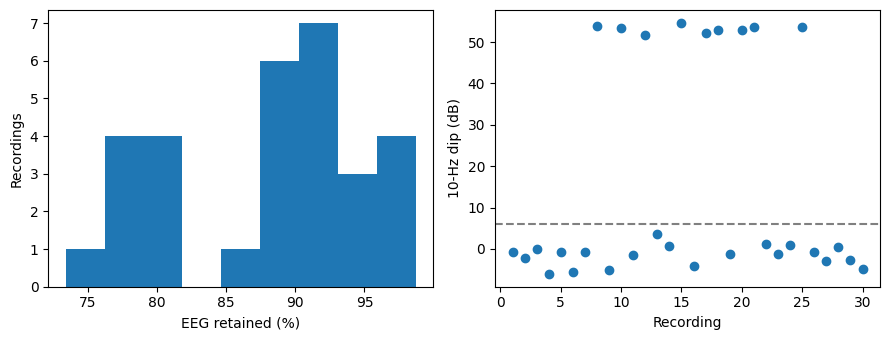

In [6]:
from scipy.signal import periodogram
def audit_edf(path):
    content = path.read_bytes()
    n = int(content[252:256]); start = int(content[184:192]); records = int(content[236:244])
    labels = [content[256+i*16:272+i*16].decode().strip() for i in range(n)]
    data = np.frombuffer(content[start:],'<i2').reshape(records,n,-1).transpose(1,0,2).reshape(n,-1)
    data = data[[i for i,name in enumerate(labels) if name!='Trig']]
    pairs = [(i,j) for i in range(len(data)) for j in range(i) if np.array_equal(data[i],data[j])]
    blocks = data[:,:data.shape[1]//4000*4000].reshape(len(data),-1,4000).astype(float)
    f,p = periodogram(blocks,500,window='hann')
    db = 10*np.log10(np.maximum(p,1e-20))
    band = lambda lo,hi: db[:,:,(f>=lo)&(f<=hi)].mean(-1)
    dip = (band(8,9)+band(11,12))/2-band(9.5,10.5)
    return path.stem, float(np.median(dip)), len(pairs)
if rebuild or not manifest.exists():
    audit=pd.DataFrame([audit_edf(p) for p in sorted(raw_dir.glob('Subject_*.edf'))],
                       columns=['subject','dip_dB','duplicate_pairs']).set_index('subject')
    accepted=audit.index[(audit.dip_dB<6)&(audit.duplicate_pairs==0)]
    assert len(accepted)==20 and sum(scores.loc[accepted,'سن']>=18)==19
    Path('joint').mkdir(exist_ok=True)
    Path('joint/manifest.json').write_text(json.dumps([(s+'.npz',(Path('out')/(s+'.npz')).stat().st_size) for s in accepted]))
    audit.to_csv('quality_audit.csv')
qc=pd.read_csv('out/quality.csv')
dip=pd.read_csv('quality_audit.csv').rename(columns={'dip_dB':'raw_dB'})
fig,ax=plt.subplots(1,2,figsize=(9,3.5))
ax[0].hist(qc.percent,bins=9);ax[0].set(xlabel='EEG retained (%)',ylabel='Recordings')
ax[1].scatter(np.arange(1,len(dip)+1),dip.raw_dB);ax[1].axhline(6,ls='--',color='grey');ax[1].set(xlabel='Recording',ylabel='10-Hz dip (dB)')
figure('01_quality')

## Additional ICA check for the recording with a duplicate channel

ICA here checks rank and spatial distribution. The main analysis applies no ICA component rejection. The plots show relative weights across channels.


rank 18


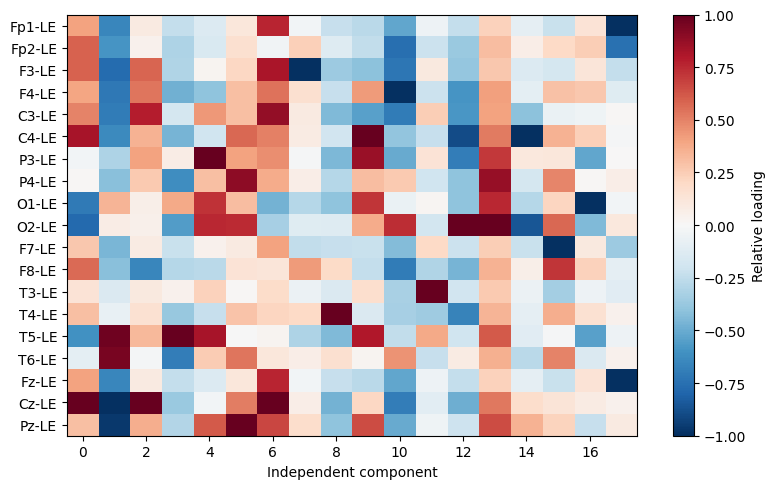

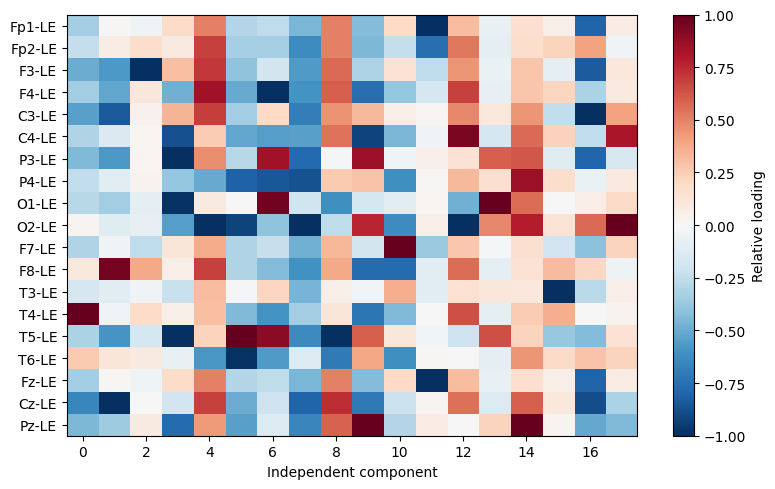

In [7]:
from scipy.signal import resample_poly
from sklearn.decomposition import FastICA
audit=pd.read_csv('quality_audit.csv').set_index('subject')
for sid in audit.index[audit.duplicate_pairs>0]:
    with np.load(work/'out'/(sid+'.npz')) as data:
        signal125=resample_poly(data['eeg'].astype(float),1,4,axis=-1)
        names=data['channels'].tolist()
    series=signal125.transpose(0,2,1).reshape(-1,len(names))
    rank=np.linalg.matrix_rank(series-series.mean(0))
    print('rank',rank)
    for seed in [17,42]:
        fitted=FastICA(n_components=rank,random_state=seed,max_iter=1000,whiten='unit-variance').fit(series)
        weights=fitted.mixing_/np.maximum(abs(fitted.mixing_).max(axis=0),1e-15)
        plt.figure(figsize=(8,5));plt.imshow(weights,aspect='auto',cmap='RdBu_r',vmin=-1,vmax=1)
        plt.yticks(range(len(names)),names);plt.xlabel('Independent component');plt.colorbar(label='Relative loading')
        figure('01_ICA_'+str(seed))